In [7]:
import pandas as pd
import numpy as np
import pickle
import shap
import matplotlib.pyplot as plt
import os

In [8]:
os.makedirs('../results', exist_ok=True)

In [9]:
xgb_model = pickle.load(open('../results/xgboost_tuned_model.pkl', 'rb'))
X_test    = pd.read_csv('../data/X_test.csv')
y_test    = pd.read_csv('../data/y_test.csv').squeeze()

In [10]:
xgb_model = pickle.load(open('../results/xgboost_tuned_model.pkl', 'rb'))
X_test    = pd.read_csv('../data/X_test.csv')
y_test    = pd.read_csv('../data/y_test.csv').squeeze()

In [12]:
X_sample = X_test.sample(n=1000, random_state=42).reset_index(drop=True)
print(f"Sample shape: {X_sample.shape}")

Sample shape: (1000, 78)


In [13]:
explainer   = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_sample)

In [14]:
np.save('../results/shap_values.npy', shap_values)
X_sample.to_csv('../results/X_sample_for_shap.csv', index=False)
print("SHAP values computed and saved.")

SHAP values computed and saved.


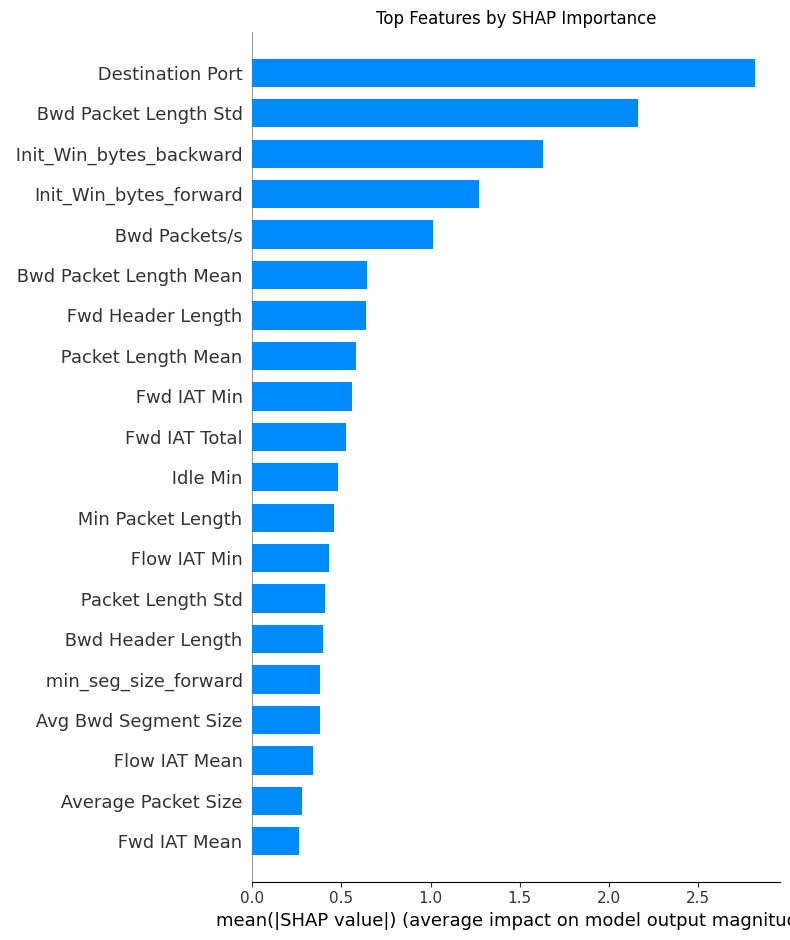

Saved shap_summary_bar.png


In [15]:
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_sample, plot_type="bar", show=False)
plt.title("Top Features by SHAP Importance")
plt.tight_layout()
plt.savefig('../results/shap_summary_bar.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved shap_summary_bar.png")

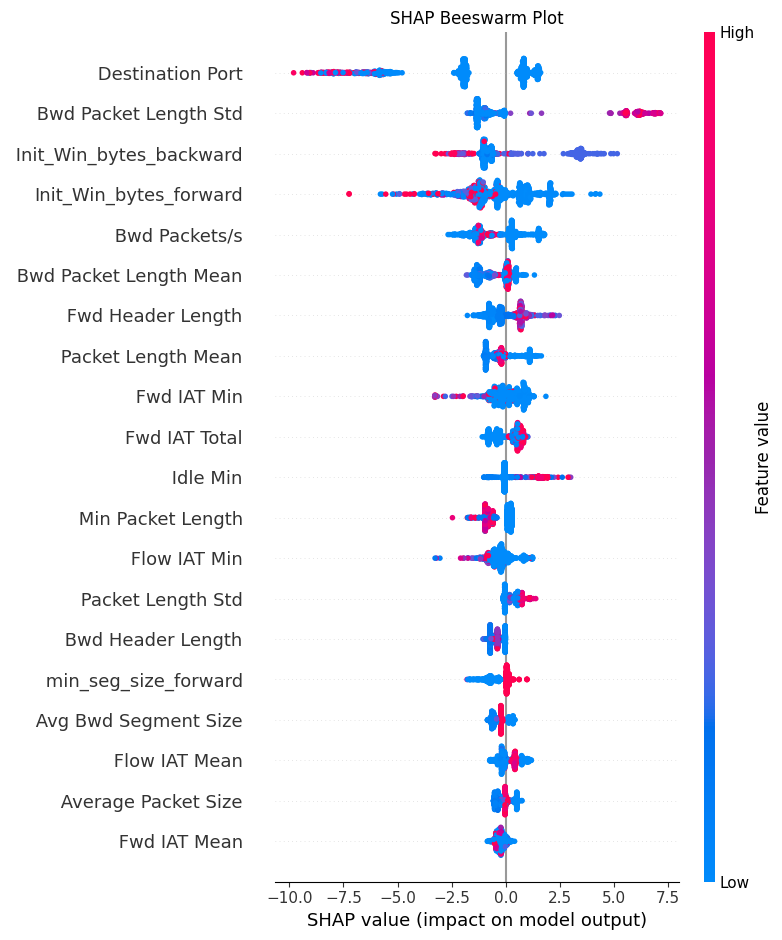

Saved shap_beeswarm.png


In [16]:
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_sample, show=False)
plt.title("SHAP Beeswarm Plot")
plt.tight_layout()
plt.savefig('../results/shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved shap_beeswarm.png")

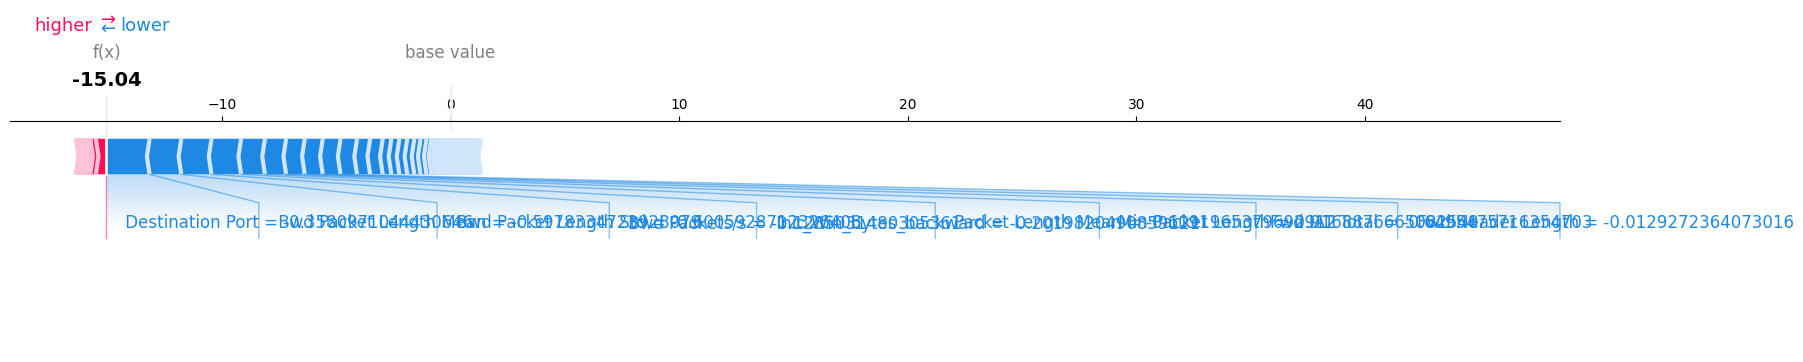

Saved shap_force_plot.png


In [17]:
# Explain first sample
idx = 0
shap.force_plot(
    explainer.expected_value,
    shap_values[idx],
    X_sample.iloc[idx],
    matplotlib=True,
    show=False
)
plt.savefig('../results/shap_force_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved shap_force_plot.png")